## __Research Question__

#### _Can we predict whether a patient has elevated blood glucose levels based on demographic characteristics, lifestyle habits, and medical data?_

##### **Create a binary target variable based on the patient's blood glucose level:**  
- **0 :** Blood glucose not elevated (< 126 mg/dL)
- **1 :** Elevated blood glucose (≥ 126 mg/dL)

### **Import required packages**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
print(os.getcwd)

<built-in function getcwd>


##### **Load and save the required csv's as a dataframe**

In [3]:
patients_df =  pd.read_csv("../Data/Patients.csv")
lifestyle_df = pd.read_csv("../Data/Hygiene_vie.csv")
glycemic_df = pd.read_csv("../Data/Historique_glycemique.csv")

In [4]:
patients_df.head()

,ID patient,Âge (ans),Sexe,Poids (kg),Taille (cm),Groupe sanguin,Glycémie (mg/dL),Insuline (µUI/mL),Corticoïdes
0,P001,37,F,48.0,157.1,O+,74.7,9.1,Non
1,P002,47,M,58.6,175.1,O+,78.0,6.3,Non
2,P003,44,F,95.0,172.2,A+,95.9,12.7,Non
3,P004,52,f,70.2,159.2,O+,96.6,6.4,Non
4,P005,58,M,99.3,172.2,A+,104.5,13.9,Oui


##### **Perform EDA on patients_df**

In [5]:
print(patients_df.shape, )
print(patients_df.isna().sum()) # print all the variables having null/missing values

(1500, 9)
ID patient           0
Âge (ans)            0
Sexe                 4
Poids (kg)           0
Taille (cm)          0
Groupe sanguin       0
Glycémie (mg/dL)     0
Insuline (µUI/mL)    0
Corticoïdes          6
dtype: int64


In [6]:
patients_df.Corticoïdes.unique() # check unique entries for Corticoïdes

<StringArray>
['Non', 'Oui', nan, 'na', 'Na']
Length: 5, dtype: str

In [7]:
patients_df.Sexe.unique() # check unique entries for sex

<StringArray>
['F', 'M', 'f', 'm', 'H', 'femme', 'h', nan, 'homme', 'Femme', 'na']
Length: 11, dtype: str

##### **Perform EDA on lifestyle_df**

In [8]:
lifestyle_df.head()

,ID patient,Stress (0-10),Niveau de stress,Sommeil (h/nuit),Activité physique (min/sem),Niveau d'activité,Fruits et légumes (portions/jour),Boissons sucrées (portions/sem),Fast-food (repas/sem),Score alimentation (0-10),Qualité de l'alimentation,Tabagisme,Alcool (unités/sem)
0,P001,6,Modéré,7.6,197.0,Élevée,2.9,3,2.2,4.8,Moyennement équilibrée,Non,3.6
1,P002,5,Modéré,6.2,166.0,Élevée,4.7,5,1.5,6.0,Moyennement équilibrée,Non,9.7
2,P003,5,Modéré,7.0,118.0,Modérée,2.2,3,1.7,1.5,Peu équilibrée,Non,0.0
3,P004,6,Modéré,7.0,156.0,Élevée,2.2,3,1.0,3.2,Peu équilibrée,Non,2.0
4,P005,7,Élevé,6.2,193.0,Élevée,1.3,1,1.5,2.4,Peu équilibrée,Oui,14.3


In [9]:
lifestyle_df.columns # list all the column names of the Patient dataFrame

Index(['ID patient', 'Stress (0-10)', 'Niveau de stress', 'Sommeil (h/nuit)',
       'Activité physique (min/sem)', 'Niveau d'activité',
       'Fruits et légumes (portions/jour)', 'Boissons sucrées (portions/sem)',
       'Fast-food (repas/sem)', 'Score alimentation (0-10)',
       'Qualité de l'alimentation', 'Tabagisme', 'Alcool (unités/sem)'],
      dtype='str')

In [10]:
lifestyle_df.shape, lifestyle_df.isna().sum() #check for null values

((1500, 13),
 ID patient                           0
 Stress (0-10)                        0
 Niveau de stress                     0
 Sommeil (h/nuit)                     0
 Activité physique (min/sem)          0
 Niveau d'activité                    0
 Fruits et légumes (portions/jour)    0
 Boissons sucrées (portions/sem)      0
 Fast-food (repas/sem)                0
 Score alimentation (0-10)            0
 Qualité de l'alimentation            0
 Tabagisme                            0
 Alcool (unités/sem)                  0
 dtype: int64)

In [11]:
lifestyle_df.dtypes  # check data types

ID patient                               str
Stress (0-10)                          int64
Niveau de stress                         str
Sommeil (h/nuit)                     float64
Activité physique (min/sem)          float64
Niveau d'activité                        str
Fruits et légumes (portions/jour)    float64
Boissons sucrées (portions/sem)        int64
Fast-food (repas/sem)                float64
Score alimentation (0-10)            float64
Qualité de l'alimentation                str
Tabagisme                                str
Alcool (unités/sem)                  float64
dtype: object

In [12]:
# keep only relevant features

lifestyle_keep = lifestyle_df[["ID patient","Sommeil (h/nuit)", "Qualité de l'alimentation", "Activité physique (min/sem)", "Tabagisme"]]
lifestyle_keep.head(3)

,ID patient,Sommeil (h/nuit),Qualité de l'alimentation,Activité physique (min/sem),Tabagisme
0,P001,7.6,Moyennement équilibrée,197.0,Non
1,P002,6.2,Moyennement équilibrée,166.0,Non
2,P003,7.0,Peu équilibrée,118.0,Non


In [13]:
lifestyle_keep.shape # verify the shape after selecting the reuired variables

(1500, 5)

##### **Perform EDA on glycemic_df**

In [14]:
glycemic_df.head()

,ID patient,Date de mesure,Glycémie (mg/dL),Poids (kg),Tension artérielle (mmHg),HbA1c (%)
0,P001,2024-11-01,89.7,50.3,97/65,7.08
1,P001,2025-03-21,69.9,47.7,117/62,6.41
2,P001,2025-03-31,76.9,44.1,125/62,6.51
3,P001,2025-04-15,75.7,44.3,105/64,6.53
4,P001,2025-05-12,71.3,45.2,105/72,5.97


In [15]:
print(glycemic_df.shape) # check the shape of glycemic_df dataFrame
print(glycemic_df["ID patient"].nunique())  # check the total of unique entries

(11565, 6)
1500


In [16]:
glycemic_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11565 entries, 0 to 11564
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID patient                 11565 non-null  str    
 1   Date de mesure             11565 non-null  str    
 2   Glycémie (mg/dL)           11565 non-null  float64
 3   Poids (kg)                 11565 non-null  float64
 4   Tension artérielle (mmHg)  11565 non-null  str    
 5   HbA1c (%)                  11565 non-null  float64
dtypes: float64(3), str(3)
memory usage: 542.2 KB


##### **Get the latest hba1c measurement**  

Since we have multiple entries per patient. For the purpose of this exercise I took the latest measurements according to the date to have one entry per patient.  
I can use Tension artérielle and HbA1c as features for predicting Elevated blood glucose.  
**They are also highly related to blood glucose.

In [17]:
# 
glycemic_df["Date de mesure"] = pd.to_datetime(glycemic_df["Date de mesure"])

latest_hba1c = (
    glycemic_df
    .sort_values("Date de mesure")
    .groupby("ID patient")
    .last()
    .reset_index()
)

latest_hba1c.shape # check whether we have the correct shape.

(1500, 6)

In [18]:
latest_hba1c.head()

,ID patient,Date de mesure,Glycémie (mg/dL),Poids (kg),Tension artérielle (mmHg),HbA1c (%)
0,P001,2026-04-18,91.8,49.8,100/61,7.01
1,P002,2026-03-26,81.0,56.5,136/65,6.68
2,P003,2026-01-09,105.9,94.2,114/59,7.68
3,P004,2026-05-12,95.9,71.0,116/70,7.36
4,P005,2026-02-05,111.8,99.5,122/73,7.77


In [19]:
latest_hba1c.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   ID patient                 1500 non-null   str           
 1   Date de mesure             1500 non-null   datetime64[us]
 2   Glycémie (mg/dL)           1500 non-null   float64       
 3   Poids (kg)                 1500 non-null   float64       
 4   Tension artérielle (mmHg)  1500 non-null   str           
 5   HbA1c (%)                  1500 non-null   float64       
dtypes: datetime64[us](1), float64(3), str(2)
memory usage: 70.4 KB


##### __merge lifestyle_keep with patients_df__

In [20]:
merged_df = patients_df.merge(
    lifestyle_keep,
    on="ID patient",
    how="left"
)

In [21]:
merged_df.head()

,ID patient,Âge (ans),Sexe,Poids (kg),Taille (cm),Groupe sanguin,Glycémie (mg/dL),Insuline (µUI/mL),Corticoïdes,Sommeil (h/nuit),Qualité de l'alimentation,Activité physique (min/sem),Tabagisme
0,P001,37,F,48.0,157.1,O+,74.7,9.1,Non,7.6,Moyennement équilibrée,197.0,Non
1,P002,47,M,58.6,175.1,O+,78.0,6.3,Non,6.2,Moyennement équilibrée,166.0,Non
2,P003,44,F,95.0,172.2,A+,95.9,12.7,Non,7.0,Peu équilibrée,118.0,Non
3,P004,52,f,70.2,159.2,O+,96.6,6.4,Non,7.0,Peu équilibrée,156.0,Non
4,P005,58,M,99.3,172.2,A+,104.5,13.9,Oui,6.2,Peu équilibrée,193.0,Oui


In [22]:
merged_df.shape

(1500, 13)

##### __merge latest_hba1c with merged_df__

In [23]:
merged_df = pd.merge(
    merged_df,
    latest_hba1c,
    on="ID patient",
    how="left"
)

In [24]:
merged_df.head()

,ID patient,Âge (ans),Sexe,Poids (kg)_x,Taille (cm),Groupe sanguin,Glycémie (mg/dL)_x,Insuline (µUI/mL),Corticoïdes,Sommeil (h/nuit),Qualité de l'alimentation,Activité physique (min/sem),Tabagisme,Date de mesure,Glycémie (mg/dL)_y,Poids (kg)_y,Tension artérielle (mmHg),HbA1c (%)
0,P001,37,F,48.0,157.1,O+,74.7,9.1,Non,7.6,Moyennement équilibrée,197.0,Non,2026-04-18,91.8,49.8,100/61,7.01
1,P002,47,M,58.6,175.1,O+,78.0,6.3,Non,6.2,Moyennement équilibrée,166.0,Non,2026-03-26,81.0,56.5,136/65,6.68
2,P003,44,F,95.0,172.2,A+,95.9,12.7,Non,7.0,Peu équilibrée,118.0,Non,2026-01-09,105.9,94.2,114/59,7.68
3,P004,52,f,70.2,159.2,O+,96.6,6.4,Non,7.0,Peu équilibrée,156.0,Non,2026-05-12,95.9,71.0,116/70,7.36
4,P005,58,M,99.3,172.2,A+,104.5,13.9,Oui,6.2,Peu équilibrée,193.0,Oui,2026-02-05,111.8,99.5,122/73,7.77


In [25]:
print(merged_df.shape)
print(merged_df.info())

(1500, 18)
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   ID patient                   1500 non-null   str           
 1   Âge (ans)                    1500 non-null   int64         
 2   Sexe                         1496 non-null   str           
 3   Poids (kg)_x                 1500 non-null   float64       
 4   Taille (cm)                  1500 non-null   float64       
 5   Groupe sanguin               1500 non-null   str           
 6   Glycémie (mg/dL)_x           1500 non-null   float64       
 7   Insuline (µUI/mL)            1500 non-null   float64       
 8   Corticoïdes                  1494 non-null   str           
 9   Sommeil (h/nuit)             1500 non-null   float64       
 10  Qualité de l'alimentation    1500 non-null   str           
 11  Activité physique (min/sem)  1500 non-null 

In [26]:
# drop features not required

main_df = merged_df.drop(columns=["ID patient", "Groupe sanguin", "Corticoïdes", "Date de mesure", "Glycémie (mg/dL)_y", "Poids (kg)_y"])

In [27]:
main_df.head()

,Âge (ans),Sexe,Poids (kg)_x,Taille (cm),Glycémie (mg/dL)_x,Insuline (µUI/mL),Sommeil (h/nuit),Qualité de l'alimentation,Activité physique (min/sem),Tabagisme,Tension artérielle (mmHg),HbA1c (%)
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,100/61,7.01
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,136/65,6.68
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,114/59,7.68
3,52,f,70.2,159.2,96.6,6.4,7.0,Peu équilibrée,156.0,Non,116/70,7.36
4,58,M,99.3,172.2,104.5,13.9,6.2,Peu équilibrée,193.0,Oui,122/73,7.77


### __PREPROCESSING__

##### **Data Cleaning**

In [28]:
# rename and clean column names for readability

main_df = main_df.rename(columns={
    "Âge (ans)": "age",
    "Sexe": "sex",
    "Poids (kg)_x": "weight_kg",
    "Taille (cm)": "height_cm",
    "Glycémie (mg/dL)_x": "glucose_mg_dl",
    "Insuline (µUI/mL)": "insulin_uIU_ml",
    "Sommeil (h/nuit)": "sleep_hours",
    "Qualité de l'alimentation": "diet_quality",
    "Activité physique (min/sem)": "physical_activity_min_week",
    "Tabagisme": "smoking",
    "Tension artérielle (mmHg)": "blood_pressure",
    "HbA1c (%)": "hba1c"
})

In [29]:
print(main_df.columns.to_list) # returns a list of the column names after cleaning

<bound method IndexOpsMixin.tolist of Index(['age', 'sex', 'weight_kg', 'height_cm', 'glucose_mg_dl',
       'insulin_uIU_ml', 'sleep_hours', 'diet_quality',
       'physical_activity_min_week', 'smoking', 'blood_pressure', 'hba1c'],
      dtype='str')>


In [30]:
main_df.head(3)

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,blood_pressure,hba1c
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,100/61,7.01
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,136/65,6.68
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,114/59,7.68


##### **Standardize sex as F or M**

In [31]:
main_df.sex.value_counts()  # check total count for unique sex classes

sex
F        923
M        561
femme      3
homme      2
Femme      2
f          1
m          1
H          1
h          1
na         1
Name: count, dtype: int64

In [32]:
main_df.sex.isna().sum() # check the total count of null/missing values

np.int64(4)

In [33]:
# replace the different classes with either F or M

main_df['sex'] = (
    main_df['sex'].str.strip()      # looks for blank spaces and strips
                     .str.lower()   # converts the sring to lowercase
                     .replace({     # replace with the correct names F or M
                        'f': 'F',
                        'femme': 'F',
                        'h': 'M',
                        'homme': 'M',
                        'm': 'M'
    })
)

In [34]:
main_df[main_df['sex'] == 'na']  # filter row with sex = na

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,blood_pressure,hba1c
176,19,na,81.8,176.3,78.2,7.4,6.7,Peu équilibrée,218.0,Oui,90/55,6.41


In [35]:
main_df['sex'] = main_df['sex'].replace('na' , np.nan) # replace na with null value

In [36]:
main_df.sex.value_counts() # check total count for unique sex classes

sex
F    929
M    566
Name: count, dtype: int64

In [37]:
main_df.dropna(inplace=True) # drop null values if any

C:\Users\fed_a\AppData\Local\Temp\ipykernel_44480\1578717128.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  main_df.dropna(inplace=True) # drop null values if any


In [38]:
# check for duplicates
main_df.duplicated().sum()

np.int64(0)

In [39]:
# check the number of rows and columns
main_df.shape

(1495, 12)

In [40]:
main_df.info()

<class 'pandas.DataFrame'>
Index: 1495 entries, 0 to 1499
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         1495 non-null   int64  
 1   sex                         1495 non-null   str    
 2   weight_kg                   1495 non-null   float64
 3   height_cm                   1495 non-null   float64
 4   glucose_mg_dl               1495 non-null   float64
 5   insulin_uIU_ml              1495 non-null   float64
 6   sleep_hours                 1495 non-null   float64
 7   diet_quality                1495 non-null   str    
 8   physical_activity_min_week  1495 non-null   float64
 9   smoking                     1495 non-null   str    
 10  blood_pressure              1495 non-null   str    
 11  hba1c                       1495 non-null   float64
dtypes: float64(7), int64(1), str(4)
memory usage: 151.8 KB


In [41]:
main_df.describe() 

,age,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,physical_activity_min_week,hba1c
count,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000
mean,50.905017,72.451237,168.785753,93.433846,9.385886,7.233244,153.685686,7.093652
std,17.862904,15.515684,10.658141,17.434931,4.150068,1.824821,88.510766,0.594995
min,18.000000,41.200000,145.000000,62.000000,2.000000,4.000000,0.000000,5.510000
25%,39.000000,60.900000,161.100000,83.200000,6.400000,6.500000,83.300000,6.710000
50%,51.000000,71.100000,168.600000,91.600000,9.100000,7.200000,146.500000,7.050000
75%,63.000000,82.550000,175.400000,100.550000,12.100000,7.900000,211.950000,7.380000
max,278.000000,128.200000,200.000000,200.900000,25.100000,64.000000,450.000000,10.350000


##### **Fix age - contains unrealistic age of 278**

In [42]:
main_df[main_df['age'] > 120]   # filter row where age>120

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,blood_pressure,hba1c
143,278,F,56.4,169.3,99.1,8.5,8.5,Peu équilibrée,251.0,Oui,121/89,7.66


In [43]:
# use median of age to replace age > 120. we keep the observation instead of deleteing it.

main_df.loc[main_df['age'] > 120, 'age'] = main_df['age'].median()

In [44]:
main_df.age.describe()

count    1495.000000
mean       50.753177
std        16.868337
min        18.000000
25%        39.000000
50%        51.000000
75%        63.000000
max        85.000000
Name: age, dtype: float64

##### __Feature Engineering__

In [45]:
# create BMI from relevant variables

main_df['BMI'] = main_df['weight_kg'] / ((main_df['height_cm'] * 100) ** 2)

In [46]:
main_df.head(3)

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,blood_pressure,hba1c,BMI
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,100/61,7.01,1.944862e-07
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,136/65,6.68,1.911284e-07
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,114/59,7.68,3.203740e-07


In [47]:
# split blood_pressure into 2 variables systolic_bp & diastolic_bp

bp_split = main_df['blood_pressure'].str.split('/', expand=True)

main_df['systolic_bp'] = bp_split[0].astype(int)
main_df['diastolic_bp'] = bp_split[1].astype(int)

In [48]:
main_df.drop(columns='blood_pressure', inplace=True) # drop the raw blood_pressure, as we have two new variables systolic_bp & diastolic_bp.

C:\Users\fed_a\AppData\Local\Temp\ipykernel_44480\2127293640.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  main_df.drop(columns='blood_pressure', inplace=True) # drop the raw blood_pressure, as we have two new variables systolic_bp & diastolic_bp.


In [49]:
main_df.head(3)

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,hba1c,BMI,systolic_bp,diastolic_bp
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,7.01,1.944862e-07,100,61
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,6.68,1.911284e-07,136,65
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,7.68,3.203740e-07,114,59


##### __Encode categorical variables__

##### _encode diet quality_

In [50]:
from sklearn.preprocessing import OneHotEncoder

print(main_df['diet_quality'].unique()) # check unique values for diet_quality
print(main_df['diet_quality'].value_counts()) # check count of unique values for diet_quality


<StringArray>
['Moyennement équilibrée', 'Peu équilibrée', 'Équilibrée']
Length: 3, dtype: str
diet_quality
Peu équilibrée            751
Moyennement équilibrée    664
Équilibrée                 80
Name: count, dtype: int64


In [51]:
# Instantiate OneHotEncoder
ohe_binary = OneHotEncoder(sparse_output=False, drop="if_binary")

# Fit encoder
ohe_binary.fit(main_df[['diet_quality']])

# Display the detected categories
print(f"The categories detected by the OneHotEncoder are {ohe_binary.categories_}")


The categories detected by the OneHotEncoder are [array(['Moyennement équilibrée', 'Peu équilibrée', 'Équilibrée'],
      dtype=object)]


In [52]:
# Display the generated names
print(f"The column names for the encoded values are {ohe_binary.get_feature_names_out()}")

# Transform the current "diet_quality" column
main_df[ohe_binary.get_feature_names_out()] = ohe_binary.transform(main_df[['diet_quality']]).astype(int)

main_df.head(3)

The column names for the encoded values are ['diet_quality_Moyennement équilibrée' 'diet_quality_Peu équilibrée'
 'diet_quality_Équilibrée']


,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,hba1c,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,7.01,1.944862e-07,100,61,1,0,0
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,6.68,1.911284e-07,136,65,1,0,0
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,7.68,3.203740e-07,114,59,0,1,0


##### _encode smoking_

In [53]:
print(main_df['smoking'].unique()) # check unique values for smoking
print(main_df['smoking'].value_counts()) # check count of unique values for smoking

<StringArray>
['Non', 'Oui']
Length: 2, dtype: str
smoking
Non    1207
Oui     288
Name: count, dtype: int64


In [54]:
# Instantiate OneHotEncoder
ohe_smoking = OneHotEncoder(sparse_output=False, drop="if_binary")

# Fit encoder
ohe_smoking.fit(main_df[['smoking']])

# Display the detected categories
print(f"The categories detected by the OneHotEncoder are {ohe_smoking.categories_}")

The categories detected by the OneHotEncoder are [array(['Non', 'Oui'], dtype=object)]


In [55]:
# Display the generated names
print(f"The column names for the encoded values are {ohe_smoking.get_feature_names_out()}")

# Transform the current "smoking" column
main_df[ohe_smoking.get_feature_names_out()] = ohe_smoking.transform(main_df[['smoking']]).astype(int)

main_df.head(3)

The column names for the encoded values are ['smoking_Oui']


,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,hba1c,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,7.01,1.944862e-07,100,61,1,0,0,0
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,6.68,1.911284e-07,136,65,1,0,0,0
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,7.68,3.203740e-07,114,59,0,1,0,0


##### _encode sex_

In [56]:
print(main_df['sex'].unique()) # check unique values for sex
print(main_df['sex'].value_counts()) # check count of unique values for sex

<StringArray>
['F', 'M']
Length: 2, dtype: str
sex
F    929
M    566
Name: count, dtype: int64


In [57]:
# Instantiate OneHotEncoder
ohe_sex = OneHotEncoder(sparse_output=False, drop="if_binary")

# Fit encoder
ohe_sex.fit(main_df[['sex']])

# Display the detected categories
print(f"The categories detected by the OneHotEncoder are {ohe_sex.categories_}")

The categories detected by the OneHotEncoder are [array(['F', 'M'], dtype=object)]


In [58]:
# Display the generated names
print(f"The column names for the encoded values are {ohe_sex.get_feature_names_out()}")

# Transform the current "sex" column
main_df[ohe_sex.get_feature_names_out()] = ohe_sex.transform(main_df[['sex']]).astype(int)

main_df.head(3)

The column names for the encoded values are ['sex_M']


,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,hba1c,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,7.01,1.944862e-07,100,61,1,0,0,0,0
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,6.68,1.911284e-07,136,65,1,0,0,0,1
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,7.68,3.203740e-07,114,59,0,1,0,0,0


##### **Create a binary target variable based on the patient's blood glucose level:**

In [59]:
# returns 1(Elevated blood_glucose) if condition is True or 0(Not elevated blood_glucose) if condition is false. Store the values returned in a new variable/column(glucose)

main_df['glucose'] = (main_df['glucose_mg_dl'] >= 126).astype(int) 

In [60]:
main_df.head(3)

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,hba1c,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M,glucose
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,7.01,1.944862e-07,100,61,1,0,0,0,0,0
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,6.68,1.911284e-07,136,65,1,0,0,0,1,0
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,7.68,3.203740e-07,114,59,0,1,0,0,0,0


In [61]:
# keep only numerical features for the final dataframe, since all categorical variables are encoded.

preprocess_df = main_df.select_dtypes(include='number')


In [62]:
preprocess_df.head(3)

,age,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,physical_activity_min_week,hba1c,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M,glucose
0,37,48.0,157.1,74.7,9.1,7.6,197.0,7.01,1.944862e-07,100,61,1,0,0,0,0,0
1,47,58.6,175.1,78.0,6.3,6.2,166.0,6.68,1.911284e-07,136,65,1,0,0,0,1,0
2,44,95.0,172.2,95.9,12.7,7.0,118.0,7.68,3.203740e-07,114,59,0,1,0,0,0,0


In [63]:
preprocess_df = preprocess_df.drop(columns=['glucose_mg_dl']) # drop the original glucose_mg_dl from the dataframe, as we have already created a binary target based on glucose_mg_dl.

In [64]:
preprocess_df.head(3)

,age,weight_kg,height_cm,insulin_uIU_ml,sleep_hours,physical_activity_min_week,hba1c,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M,glucose
0,37,48.0,157.1,9.1,7.6,197.0,7.01,1.944862e-07,100,61,1,0,0,0,0,0
1,47,58.6,175.1,6.3,6.2,166.0,6.68,1.911284e-07,136,65,1,0,0,0,1,0
2,44,95.0,172.2,12.7,7.0,118.0,7.68,3.203740e-07,114,59,0,1,0,0,0,0


#### **Select the target(dependent y) variable and the features(Independent X) variables**

In [65]:
# select the features and target for modeling

X = preprocess_df.drop(columns=['glucose']) # all columns except target
y = preprocess_df['glucose'] # select target variable

**Check for Multicollinearity**  
*since BMI was derived from weight and height variables, there is a possibility for multicollinearity.*  
*As well as, we can check for other variables*.

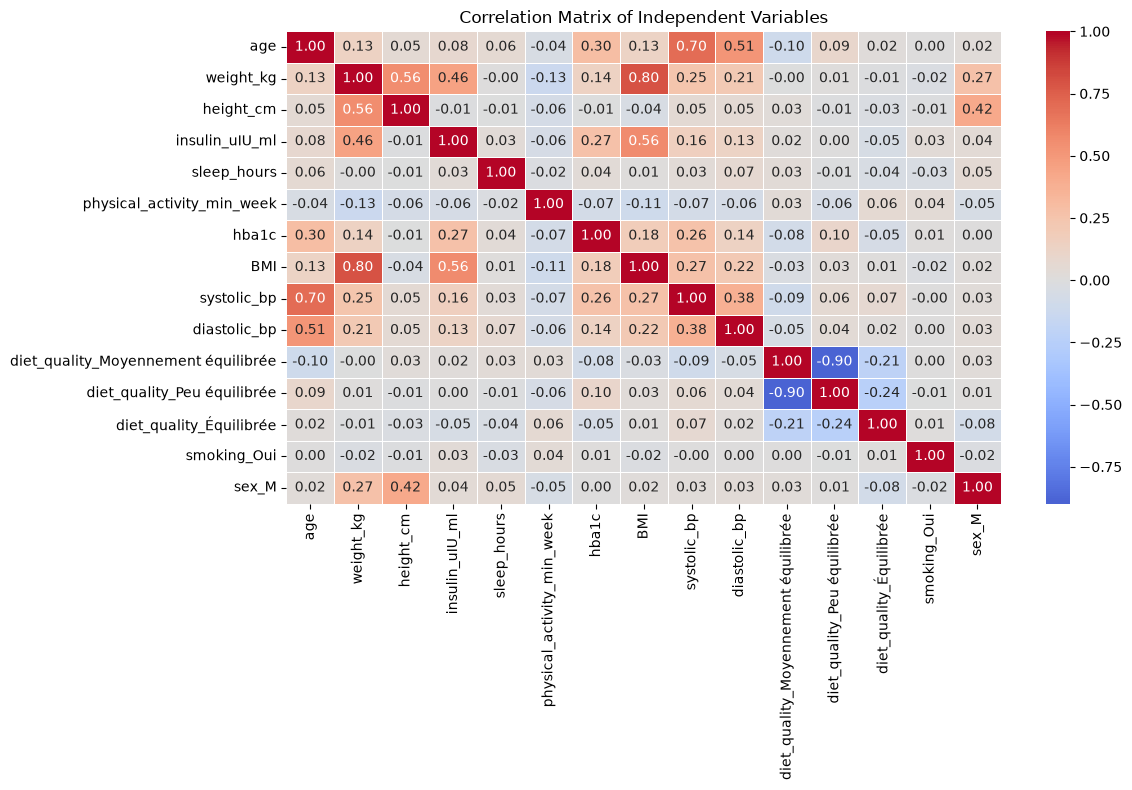

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix using training features
corr_matrix = X.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Independent Variables")
plt.tight_layout()
plt.show()

Since weight and BMI are highly corelated. we can drop weight for model training

In [67]:
X = X.drop(columns=['weight_kg'])

In [68]:
X.head(3)

,age,height_cm,insulin_uIU_ml,sleep_hours,physical_activity_min_week,hba1c,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M
0,37,157.1,9.1,7.6,197.0,7.01,1.944862e-07,100,61,1,0,0,0,0
1,47,175.1,6.3,6.2,166.0,6.68,1.911284e-07,136,65,1,0,0,0,1
2,44,172.2,12.7,7.0,118.0,7.68,3.203740e-07,114,59,0,1,0,0,0


##### **Train_Test_Split data**

In [69]:
# Always split first, then fit the scaler on the training set only to avoid data leakage.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [70]:
print(f"X_train_shape : {X_train.shape}")   # check X_train shape
print(f"X_test_shape : {X_test.shape}")     # check X_test shape
print(f"y_train_shape : {y_train.shape}")   # check y_train shape
print(f"y_test_shape : {y_test.shape}")     # check y_test shape

X_train_shape : (1196, 14)
X_test_shape : (299, 14)
y_train_shape : (1196,)
y_test_shape : (299,)


In [71]:
print(type(y_test))

<class 'pandas.Series'>


#### **Scaling Features X**

In [72]:
# Scale(fit_transform) only the traning set(X_train) and use (transform) on the test set(X_test), to avoid data leakage.

from sklearn.preprocessing import MinMaxScaler

# Instantiate minmax Scaler
minmax_scaler = MinMaxScaler()

X_train_scaled = pd.DataFrame(minmax_scaler.fit_transform(X_train), 
                              columns=X_train.columns,
                              index=X_train.index)    # convert the scaled data into a dataframe and retain the X_train column names and index

X_test_scaled = pd.DataFrame(minmax_scaler.transform(X_test),
                             columns=X_test.columns,
                             index=X_test.index)      # convert the scaled data into a dataframe and retain the X_test column names and index

In [73]:
X_train_scaled.head(3)

,age,height_cm,insulin_uIU_ml,sleep_hours,physical_activity_min_week,hba1c,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M
537,0.582090,0.330909,0.212121,0.666667,0.456889,0.287190,0.325250,0.506849,0.432432,0.0,1.0,0.0,0.0,1.0
539,0.776119,0.350909,0.402597,0.716667,0.272000,0.477273,0.155900,0.506849,0.216216,0.0,1.0,0.0,0.0,0.0
1341,0.761194,0.616364,0.155844,0.700000,0.664444,0.247934,0.092885,0.616438,0.135135,1.0,0.0,0.0,1.0,0.0


In [74]:
print(f"X_train_scaled_shape : {X_train_scaled.shape}")
print(f"X_test_scaled_shape : {X_test_scaled.shape}")

X_train_scaled_shape : (1196, 14)
X_test_scaled_shape : (299, 14)


## **3. Training Two Models**

#### **Train a Logistic Regression (baseline model).** 

In [75]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_log = lr_model.predict(X_test_scaled)
y_prob_log = lr_model.predict_proba(X_test)[:, 1]

#### **Train a XGBoost model** 

In [76]:
from xgboost import XGBClassifier

# Create initial model
xgb_model = XGBClassifier(
    objective="binary:logistic",
    random_state=42,
    eval_metric='logloss'
)


**Optimize the XGBoost model by tuning Hyperparameters**

In [77]:
# Hyperparameter tuning using Grid Search
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
# Scaling is not rquired for a decision tree model
grid_search.fit(X_train, y_train)


Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.1, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metr

##### __*Specify the metric used to select the best hyperparameter combination and justify your choice.*__

**Evaluation Metric**: Recall (Sensitivity)  
**Recall** was selected as the primary evaluation metric for hyperparameter optimization using Grid Search with 5-fold cross-validation.  
Recall measures the proportion of actual positive cases (elevated blood glucose) correctly identified by the model.

**Justification:**
  
- **False Negatives (FN):** Elevated glucose cases incorrectly classified as normal.  
- **False Positives (FP):** Normal glucose cases incorrectly classified as elevated.  

In this health-related prediction task, false negatives are particularly concerning because potentially elevated glucose levels may go undetected.  
Therefore, maximizing recall helps minimize missed positive cases, making it an appropriate metric for selecting the best XGBoost hyperparameter combination.

In [78]:
print("Best Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Recall:")
print(grid_search.best_score_)

Best Hyperparameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}

Best Cross-Validation Recall:
0.8714285714285716


In [79]:
# Retrieve the best model
best_xgb_model = grid_search.best_estimator_

In [80]:
# Predictions
y_pred_xgb = best_xgb_model.predict(X_test)

# Predicted probabilities
y_prob_xgb = best_xgb_model.predict_proba(X_test)[:, 1]

### **5. Evaluation and Comparison of Models**

##### **Evaluate the baseline(Logistic Regression Model)**

In [81]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1-score:", f1_score(y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_log))


Logistic Regression Results
---------------------------
Accuracy: 0.9464882943143813
Precision: 0.75
Recall: 0.16666666666666666
F1-score: 0.2727272727272727
ROC-AUC: 0.617141162514828


##### **Evaluate optimized XGBoost model**

In [82]:
print("XGBoost Results")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1-score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))


XGBoost Results
---------------------------
Accuracy: 0.979933110367893
Precision: 0.9285714285714286
Recall: 0.7222222222222222
F1-score: 0.8125
ROC-AUC: 0.9857651245551602


**Display the confusion matrix:**

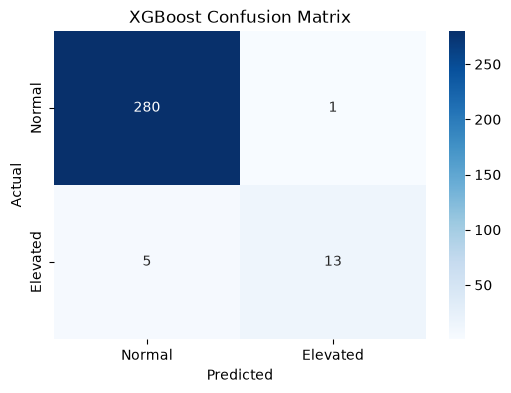

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Elevated"],
    yticklabels=["Normal", "Elevated"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")
plt.show()

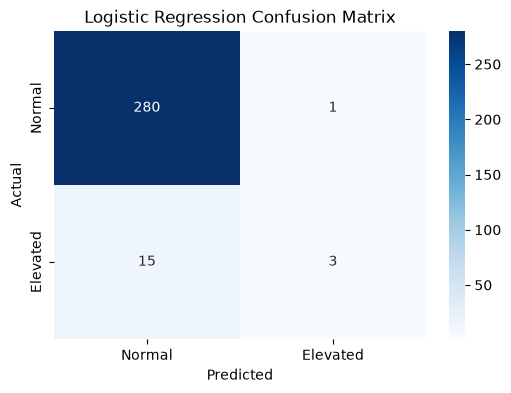

In [84]:
cm1 = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm1,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Elevated"],
    yticklabels=["Normal", "Elevated"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

**Comparison of models**

In [85]:
# comparison table to determine which model performs better.

results = pd.DataFrame({
    "Model": ["Logistic Regression", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_xgb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_xgb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_xgb)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_xgb)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

results.set_index("Model").round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.946,0.750,0.167,0.273,0.617
XGBoost,0.980,0.929,0.722,0.812,0.986


**Observed Differences**  

- ***Accuracy***: XGBoost achieves an accuracy of 98.0%, compared to 94.6% for Logistic Regression, indicating better overall classification performance.  
- ***Precision***: XGBoost achieves 92.9%, compared to 75.0% for Logistic Regression. This indicates that XGBoost generates fewer false positive predictions.

- ***Recall***: The most significant improvement is observed in recall, increasing from 16.7% with Logistic Regression to 72.2% with XGBoost.  
This means that XGBoost identifies a considerably larger proportion of individuals with elevated blood glucose levels. Thereby by **reducing False neagtives**.

- ***F1-score***: XGBoost achieves 81.2%, compared to 27.3% for Logistic Regression, demonstrating a much better balance between precision and recall.

- ***ROC-AUC***: XGBoost achieves 98.6%, compared to 61.7% for Logistic Regression, indicating a substantially stronger ability to distinguish between normal and elevated blood glucose cases.

**Model Selection**  

I would choose **XGBoost** for predicting elevated blood glucose levels.

**Justification**

***1. Predictive performance***

XGBoost outperforms Logistic Regression across all evaluation metrics, achieving:
- Accuracy: 98.0% vs. 94.6%.
- Precision: 92.9% vs. 75.0%.
- Recall: 72.2% vs. 16.7%.
- F1-score: 81.2% vs. 27.3%.
- ROC-AUC: 98.6% vs. 61.7%.
These results indicate that XGBoost provides a considerably better balance between identifying elevated glucose cases and avoiding false positive predictions.

***2. Risk of false negatives***

In this particular application, false negatives are an important concern because individuals with elevated blood glucose may be incorrectly classified as having normal levels.  
Logistic Regression identifies only 16.7% of actual positive cases, whereas XGBoost identifies 72.2%.

Although XGBoost still misses approximately 27.8% of positive cases, it represents a substantial improvement over Logistic Regression.

***3. Ease of interpretation***

Logistic Regression has an advantage in interpretability because its coefficients provide a relatively straightforward indication of how individual features influence the predicted outcome.  
XGBoost is more complex and less straightforward to interpret.

### **6. Model Interpretation**

**A. Logistic Regression**

In [86]:
# coefficients of the logistic regression model as s Dataframe
coefficients = pd.DataFrame({
    "Feature": lr_model.feature_names_in_,
    "Coefficient": lr_model.coef_[0]
})

# Calculate odds ratios, since the coefficients are in log odds space.
coefficients["Odds_Ratio"] = np.exp(
    coefficients["Coefficient"]
)

# Sort by Odds Ratio
coefficients = coefficients.sort_values(by='Odds_Ratio', ascending=False)

# view the coefficients DataFrame
coefficients[[
    "Feature",
    "Coefficient",
    "Odds_Ratio"
]].reset_index(drop=True).round(3)



,Feature,Coefficient,Odds_Ratio
0,hba1c,5.719,304.634
1,age,1.806,6.088
2,insulin_uIU_ml,1.782,5.941
3,sleep_hours,1.291,3.636
4,systolic_bp,1.251,3.495
5,sex_M,0.524,1.689
6,diet_quality_Peu équilibrée,0.321,1.379
7,diastolic_bp,0.316,1.372
8,BMI,0.098,1.103
9,diet_quality_Moyennement équilibrée,0.066,1.068


**Identify variables associated with an increased probability of elevated blood glucose.**  

In order of strongly associated with increased probability of elevated blood glucose.    
- *hba1c, age, insulin_uIU_ml, sleep_hours, systolic_bp, sex_M, BMI*

**Identify variables associated with a decreased probability of elevated blood glucose.**  
- *physical_activity_min_week, smoking_Oui, diet_quality_Équilibrée*

**Determine which variables appear to have the strongest association with the target variable.**  
- *hba1c, age, insulin_uIU_ml, sleep_hours, systolic_bp, physical_activity_min_week*

**B. XGBoost and SHAP**

In [87]:
import shap

**A global SHAP summary plot (beeswarm plot) showing the most influential variables.**

In [88]:
# Create SHAP explainer
explainer = shap.TreeExplainer(best_xgb_model)

# Calculate SHAP values for test data
shap_values = explainer(X_test)

print(shap_values.shape)
print(best_xgb_model.classes_)

(299, 14)
[0 1]


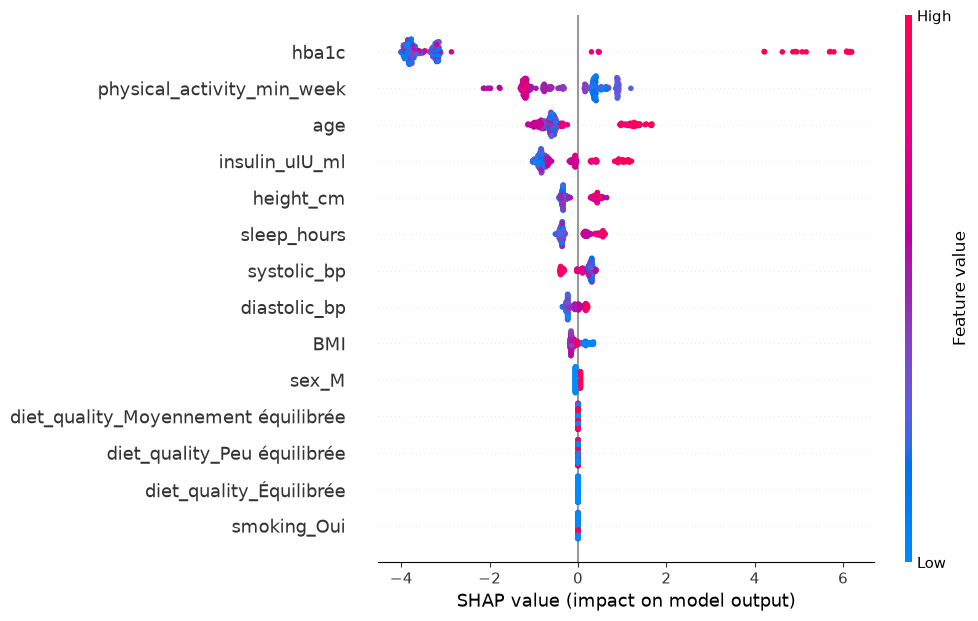

In [89]:
# SHAP summary plot
shap.plots.beeswarm(shap_values, max_display=15)

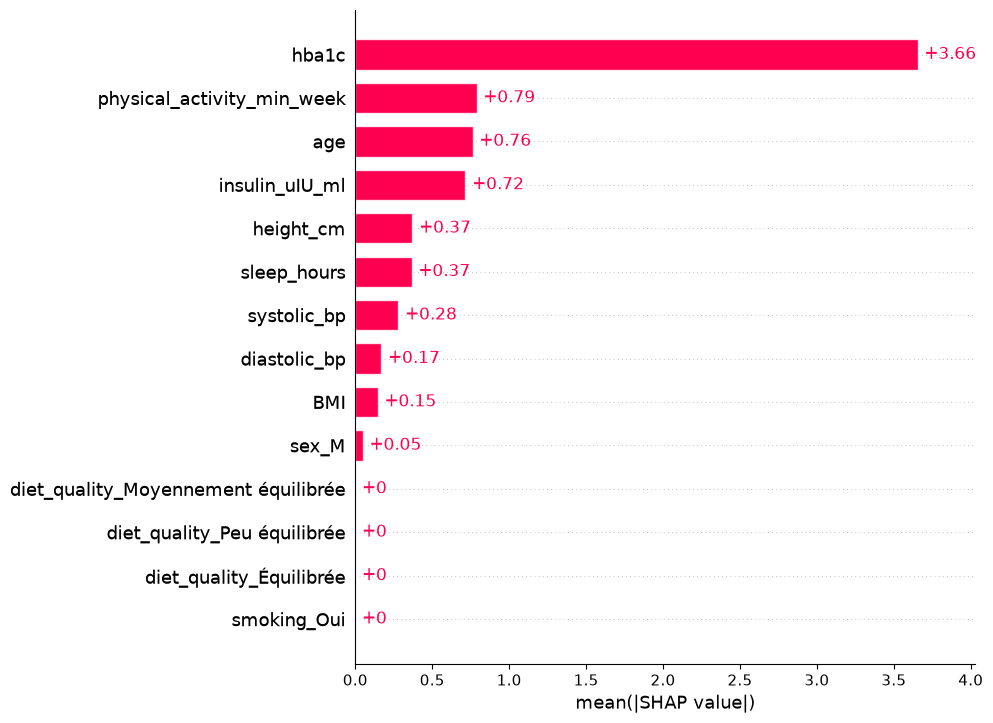

In [90]:
# feature importance – SHAP bar plot
shap.plots.bar(shap_values, max_display=15)

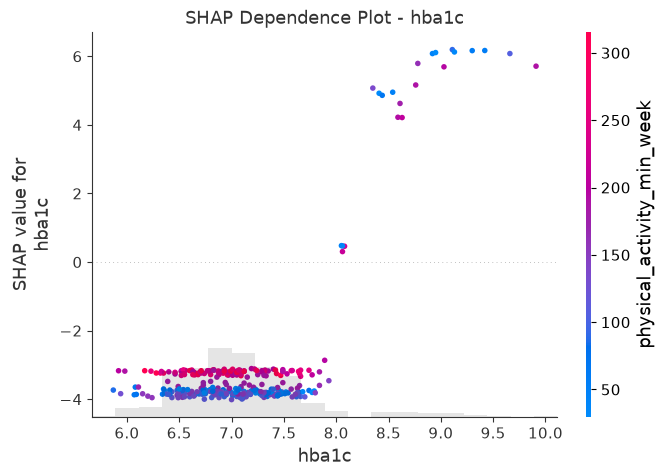

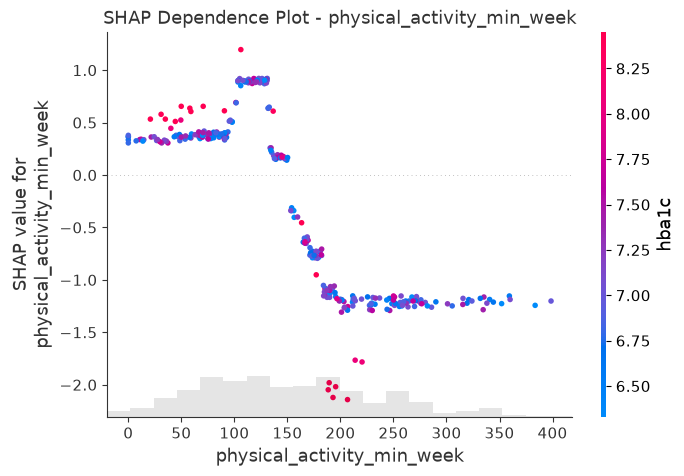

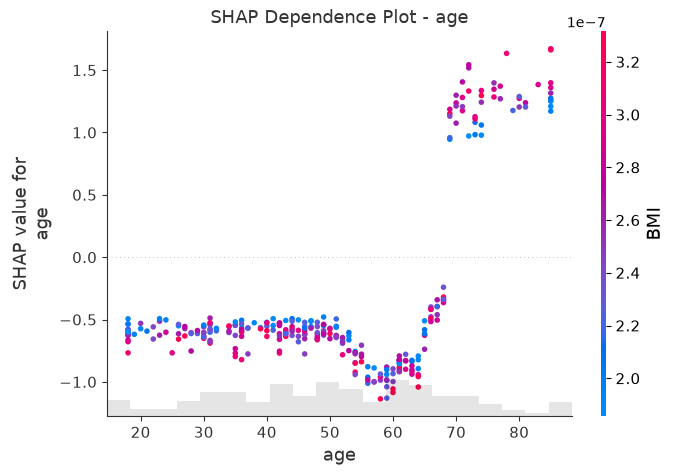

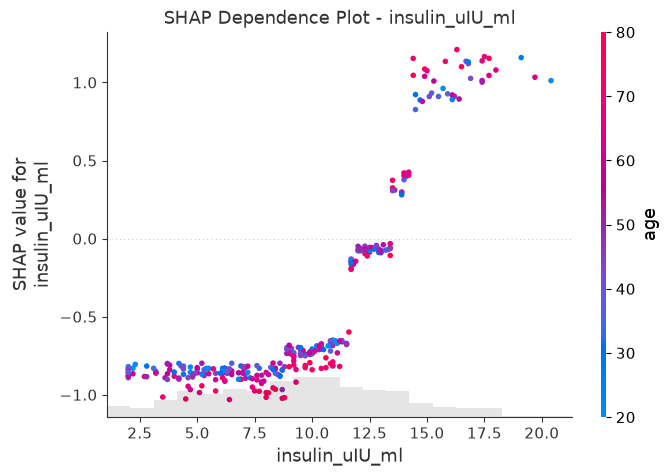

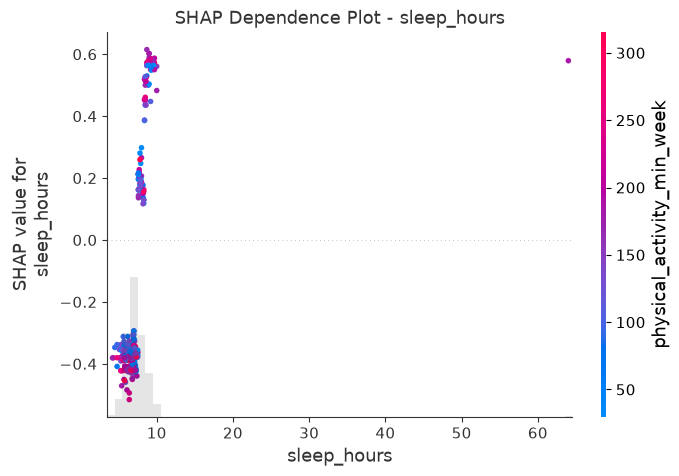

In [91]:
# Scatter plots showing the relationship between feature values and their contribution to predictions. 

features = ['hba1c', 'physical_activity_min_week', 'age', 'insulin_uIU_ml', 'sleep_hours']

for feature in features:
    shap.plots.scatter(
        shap_values[:, feature],
        color=shap_values,
        title=f"SHAP Dependence Plot - {feature}"
    )

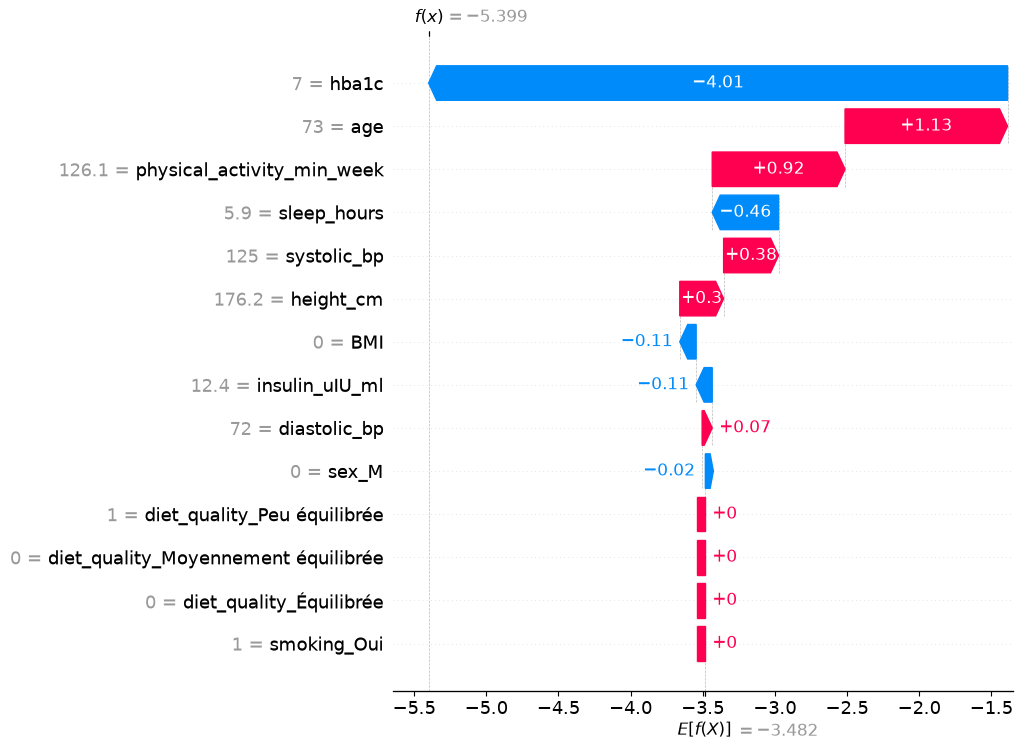

In [92]:
# A local explanation of an individual prediction / Explain the first test observation
shap.plots.waterfall(shap_values[0], max_display=15)

#### **Compare the insights obtained from SHAP with those from the logistic regression model.**

Both the logistic regression model and the SHAP analysis identified similar key predictors of elevated blood glucose,  
but they provide different types of information.  

**Agreements Between the Two Methods**  

**- HbA1c is the strongest predictor**

Both methods identified HbA1c as the most influential variable.  
- Logistic regression showed a very large positive coefficient and odds ratio.    
- SHAP ranked HbA1c as the most important feature and showed that **values above approximately 8 strongly increase the prediction of elevated blood glucose**, while lower values strongly decrease it.  

**- Age increases the risk of elevated blood glucose**

Logistic regression:  

- Positive coefficient for age.    
- Older individuals have higher odds of elevated blood glucose.

SHAP:

- Older ages produce positive SHAP values.  
- In the local explanation, age contributed +1.13 to the prediction.

**- Insulin is positively associated with elevated glucose**

Logistic regression:

- Positive coefficient.
- Higher insulin levels increase the odds of elevated glucose.

SHAP:

- Higher insulin values generally contribute positively to model predictions.

**- Physical activity has an important effect**

Logistic regression:

- Negative coefficient.
- Higher physical activity is associated with lower odds of elevated glucose.

SHAP:

- Physical activity is among the most important predictors.
- Dependence plots show that activity levels influence model predictions substantially.

### **7. Discussion of Results**


- hba1c
- Age
- physical activity
- insulin level  
- systolic bp  
Above variables appear to be most strongly associated with glycemic status.  

Higher HbA1c levels, older age, elevated insulin concentrations, and higher blood pressure were associated with an increased probability of elevated blood glucose.  
Both models highlighted largely the same important factors. Logistic regression identified **HbA1c, age, insulin levels, physical activity, sleep duration,   
and blood pressure** as the variables most strongly associated with glycemic status, while the **SHAP summary plot ranked HbA1c, physical activity, age, and insulin** among the most important features driving predictions.  

XGBoost provided a substantial improvement in predictive performance.  
Based on the above comparison table, logistic regression achieved a relatively high accuracy (0.946), its recall (0.167), F1-score (0.273), and ROC-AUC (0.617) were poor,  
indicating limited ability to correctly identify individuals with elevated blood glucose.  

In contrast, XGBoost achieved higher values across all metrics, including an accuracy of 0.980, precision of 0.929, recall of 0.722, F1-score of 0.812, and ROC-AUC of 0.986.  

Several limitations should be considered. First, the sample size appears relatively modest, which may limit the findings or the predictions of the model.  
Second, the data quality may affect the results, because the data is fictitious and maybe subject to measurement and reporting errors.  
Third, there is always a potential risk of overfitting, especially for XGBoost.  
And the feature **hba1c** which is closely linked to blood glucose and therefore acts as a powerful predictor without necessarily providing insight into the underlying causes of glycemic status.  

Overall, both modeling approaches indicate that glycemic status is primarily driven by features such as HbA1c, age, insulin levels, and physical activity.  
logistic regression offers clear interpretability, XGBoost provides better predictive performance and, when combined with SHAP, provides both accurate predictions and meaningful explanations of the factors influencing glucose status.  